# Graph Mining I: who matters in a network?
## Who asks whom for help with coursework
**Salem Othman · Student notebook · Self-study class, Wednesday, November 4**

**There is no class meeting today.** Work through this notebook on your own, in order, during class time (3:00–4:45 PM) or later the same day. Everything you need is explained here, and the slides `GM1_Slides.pptx` draw each algorithm step by step. Read the slide named in each part before you start that part.

**Submit** this notebook with all outputs in Brightspace by **Wednesday, November 4, 11:59 PM**. It counts as today's in-class exercise.

---

So far every dataset was a **table**: one row per customer, per message, per scooter. Some data is about **connections** instead: who follows whom, which web page links to which, which bank account sends money to which. That is a **graph** (also called a **network**), and graph mining asks questions a table can't answer easily:

- Who is the most connected?
- Who holds the network together, so that it falls apart without them?
- Whose opinion counts most, because the people who matter listen to them?

Today's data: 60 students and **who asks whom for help** with coursework. It is **practice data, generated by code for this exercise** (so everyone gets the same network); the students and the help log are not real.

### Today's five steps
| Part | Step | What you do | Slides | Exercise |
|---|---|---|---|---|
| 1 | Build | Turn the help log into a graph | 3–6 | E1 |
| 2 | Degree | Count each student's links | 7–8 | E2 |
| 3 | Paths | Find how many hand-offs separate two students | 9–14 | E3 |
| 4 | Bridges | Find who holds the network together | 15–20 | E4 |
| 5 | PageRank | Rank students by who asks them | 21–26 | E5 |

**How to work**
- Run cells from top to bottom with **Shift + Enter**.
- In an exercise cell, **write the code yourself** under each numbered step. Keep the variable names exactly as written; the Check cell looks for them.
- `PASS` means that step is done. `FIX` tells you what to look at.
- If a Check cell says an exercise **is not finished yet**, that is not an error: write the code in the exercise cell above, run it, then run the Check cell again.
- **Setup problem?** If the first code cell says `ModuleNotFoundError: No module named 'networkx'` (or pandas, numpy, matplotlib), run `%pip install networkx` (or the missing name) in a new cell, then **Kernel → Restart** and run from the top. Still failing? Open the notebook in Google Colab (File → Upload notebook): all four libraries are already installed there.
- **Stuck for more than 10 minutes?** Re-read the explanation above the exercise and the hints. Then post your question in the Brightspace discussion, with the error message, and move on to the next part. You may ask an AI tool to **explain** an error, not to write the exercise.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
RANDOM_STATE = 42

MAJOR_COLORS = {"Computer Science": "#2a78d6", "Data Science": "#eb6834",
                "Mechanical Eng": "#1baf7a", "Architecture": "#eda100"}


def draw_network(graph, students, highlight=(), title="", size=None):
    """Draw the network: one dot per student, coloured by major. Names in `highlight` get a label.

    size: optional dict {name: number} to make some dots bigger.
    """
    pos = nx.spring_layout(graph.to_undirected(), seed=7)
    major = dict(zip(students["name"], students["major"]))
    sizes = [60 + 900 * size[n] / max(size.values()) if size else 80 for n in graph.nodes]
    fig, ax = plt.subplots(figsize=(9, 7))
    nx.draw_networkx_edges(graph.to_undirected(), pos, ax=ax, alpha=0.25, width=0.8)
    nx.draw_networkx_nodes(graph, pos, ax=ax, node_size=sizes,
                           node_color=[MAJOR_COLORS[major[n]] for n in graph.nodes], edgecolors="white")
    nx.draw_networkx_labels(graph, pos, ax=ax, labels={n: n for n in highlight}, font_size=11, font_weight="bold")
    for name, colour in MAJOR_COLORS.items():
        ax.scatter([], [], color=colour, label=name)
    ax.legend(frameon=False, loc="lower left")
    ax.set_title(title)
    ax.axis("off")
    plt.show()


def check(label, passed):
    """Print PASS or FIX for one requirement."""
    print(("PASS  " if passed else "FIX   ") + label)

def ready(value, step):
    """True when the exercise above is done. Otherwise print a reminder and return False.

    It never raises, so a blank exercise cell can never stop the class with a red
    traceback: the Check cell just tells the student what to do next.
    """
    if value is None:
        print(f"{step} is not finished yet.")
        print("Write your code in the exercise cell above, run that cell, then run this one again.")
        return False
    return True

print("networkx version:", nx.__version__)
print("Setup complete.")

networkx version: 3.7
Setup complete.


# Part 0 · The data
Two tables.

`students`: one row per student.

| Column | Meaning |
|---|---|
| `name` | The student (first names are unique in this class) |
| `major` | Computer Science, Data Science, Mechanical Eng or Architecture |

**Practice data:** both tables are generated by the code in the next cell, built to look like a library's study-help survey.

`help_log`: one row per pair of students where one asked the other for help this term.

| Column | Meaning |
|---|---|
| `asker` | The student who asked for help |
| `helper` | The student who was asked |
| `times` | How many times this term (we won't need it today) |

In [2]:
rng = np.random.default_rng(1104)

# 60 students who use the library's study rooms. When one student asks another for help with
# coursework (in person or on the course chat), the library's study-help survey records it.
names = ["Ava", "Liam", "Noah", "Emma", "Mia", "Ethan", "Zoe", "Lucas", "Aria", "Mason",
         "Leo", "Nora", "Omar", "Ivy", "Ryan", "Lily", "Sam", "Grace", "Jack", "Chloe",
         "Owen", "Ruby", "Adam", "Hana", "Eli", "Maya", "Finn", "Sara", "Theo", "Lena",
         "Kai", "Iris", "Ben", "Yara", "Max", "Elle", "Dev", "Rosa", "Jay", "Nina",
         "Alex", "Tara", "Luca", "Amir", "Jade", "Cole", "Rhea", "Ian", "Mila", "Hugo",
         "Ana", "Reza", "Tess", "Gabe", "Lina", "Wes", "June", "Pablo", "Dina", "Rami"]
majors = ["Computer Science"] * 18 + ["Data Science"] * 15 + ["Mechanical Eng"] * 15 + ["Architecture"] * 12
students = pd.DataFrame({"name": names, "major": majors})

def asks(group, p):
    """Every ordered pair (a asks b) inside a group happens with probability p."""
    return [(a, b) for a in group for b in group if a != b and rng.random() < p]

by_major = students.groupby("major")["name"].apply(list)
edges = []
for major, people in by_major.items():
    edges += asks([p for p in people if p != "Ana"], 0.16)

# A robotics team: 3 Computer Science and 3 Mechanical Eng students who work together every week.
robotics = ["Lucas", "Aria", "Leo", "Jay", "Nina", "Cole"]
edges += asks(robotics, 0.7)
# Omar (Computer Science) tutors: lots of students from three majors ask him for help.
for person in rng.choice(by_major["Computer Science"] + by_major["Data Science"] + by_major["Mechanical Eng"], 16, replace=False):
    if person != "Omar":
        edges.append((person, "Omar"))
# When Omar is stuck himself, he asks Nora.
edges += [("Omar", "Nora")]
# Architecture mostly keeps to itself. Ana is the only Architecture student who also
# works with two Mechanical Eng students.
edges += [("Ana", "Mila"), ("Hugo", "Ana"), ("Ana", "June"), ("Ana", "Max"), ("Elle", "Ana")]
# Every student asked or helped at least one classmate.
linked = {p for e in edges for p in e}
for person, major in zip(names, majors):
    if person not in linked:
        edges.append((person, rng.choice([p for p in by_major[major] if p != person and p != "Ana"])))

# Friends of friends: two students who both work with the same two or more classmates
# often end up asking each other too.
pairs = {frozenset(e) for e in edges}
neighbours = {p: set() for p in names}
for a, b in edges:
    neighbours[a].add(b); neighbours[b].add(a)
for i, a in enumerate(names):
    for b in names[i + 1:]:
        if frozenset((a, b)) not in pairs and not {"Ana", "Omar", "Nora"} & {a, b} and len(neighbours[a] & neighbours[b]) >= 2 and rng.random() < 0.35:
            edges.append((a, b))

help_log = (pd.DataFrame(edges, columns=["asker", "helper"]).drop_duplicates()
              .assign(times=lambda d: rng.integers(1, 9, len(d)))
              .sample(frac=1, random_state=1).reset_index(drop=True))

print("Students:", len(students), "| help-log rows:", len(help_log))
display(students["major"].value_counts())
display(help_log.head())

Students: 60 | help-log rows: 200


major
Computer Science    18
Data Science        15
Mechanical Eng      15
Architecture        12
Name: count, dtype: int64

,asker,helper,times
0,Sam,Ethan,6
1,Lucas,Liam,4
2,Mia,Zoe,7
3,Ben,Sara,2
4,Adam,Theo,8


# Part 1 · From a table to a graph  *(slides 3–6)*
A **graph** has:
- **nodes** (also called vertices): here, the students
- **edges** (also called links): here, "this student asked that student for help"

The edges have a **direction**: Lucas asking Aria is not the same as Aria asking Lucas. A graph with directions is a **directed graph**. Some questions need the direction ("who gets asked the most?"); others only care whether two students are linked at all. For those we use the **undirected** version, where an edge means "**at least one of these two asked the other** for help this term".

Be careful what an undirected edge does **not** say: it doesn't mean the two help each other, or meet regularly. Ben asking Aria once gives the same edge as Lucas and Aria asking each other every week.

`networkx` (imported as `nx`) is the standard Python library for graphs:

```python
G = nx.from_pandas_edgelist(help_log, source="asker", target="helper", create_using=nx.DiGraph)
G.add_nodes_from(students["name"])   # make sure every student is a node
U = G.to_undirected()                # the same graph without directions
G.number_of_nodes(), G.number_of_edges()
```

**Density** = the share of all possible links that actually exist. With 60 students there are 60 × 59 / 2 = 1,770 possible pairs. Real social networks are **sparse**: most pairs are not connected.

### E1 · Build the graph
**Predict:** will more or less than 20% of all possible pairs of students be connected?

In [3]:
# 1. G: a directed graph from help_log, asker -> helper. Then add every student as a node.
G = nx.from_pandas_edgelist(help_log, source="asker", target="helper", create_using=nx.DiGraph)
G.add_nodes_from(students["name"])

# 2. U: the undirected version of G.
U = G.to_undirected()

# 3. density: the density of U.
density = nx.density(U)

# 4. Print the number of nodes, the number of edges of G and of U, and the density.
print(f"Nodes: {G.number_of_nodes()}, G edges: {G.number_of_edges()}, U edges: {U.number_of_edges()}, Density: {density:.4f}")


Nodes: 60, G edges: 200, U edges: 180, Density: 0.1017


**Check E1**

In [4]:
if ready(G, "E1") and ready(U, "E1") and ready(density, "E1"):
    check("every student is a node", G.number_of_nodes() == len(students))
    check("G has one directed edge per help-log row", G.number_of_edges() == len(help_log))
    check("G is directed and U is not", G.is_directed() and not U.is_directed())
    check("density is links / possible pairs",
          np.isclose(density, U.number_of_edges() / (len(students) * (len(students) - 1) / 2)))

PASS  every student is a node
PASS  G has one directed edge per help-log row
PASS  G is directed and U is not
PASS  density is links / possible pairs


### Worked example · Look at the network
Each dot is a student, coloured by major. Nodes that are connected are pulled together, so groups of students who ask each other form clumps.

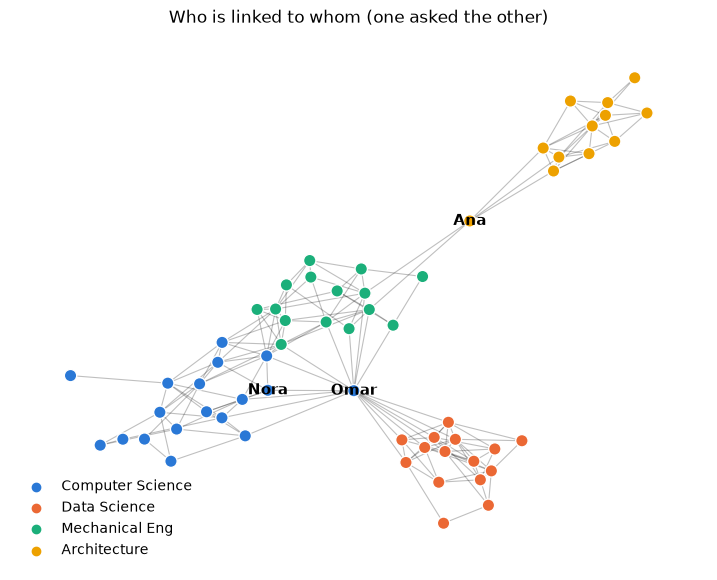

In [5]:
if ready(U, "E1"):
    draw_network(U, students, highlight=["Omar", "Ana", "Nora"], title="Who is linked to whom (one asked the other)")

**Write:** (a) Why are there fewer undirected edges than directed ones? (b) Describe the picture: what clumps do you see, and where are Omar, Ana and Nora?

*Your answer:*

# Part 2 · Degree: how many links?  *(slides 7–8)*
The **degree** of a node is how many edges touch it. It is the simplest "importance" measure: how many classmates you are linked to (you asked them, or they asked you).

In a directed graph, degree splits in two:
- **in-degree**: arrows coming in, how many students **ask you** for help
- **out-degree**: arrows going out, how many students **you ask**

```python
dict(U.degree())       # {name: number of links}
dict(G.in_degree())    # {name: how many ask them}
dict(G.out_degree())   # {name: how many they ask}
```

### E2 · Who is the most connected?
**Predict:** will the most-asked student be the one who asks the most people, too?

In [6]:
# 1. degree_table: a copy of students with three new columns:
degree_table = students.assign(
    degree=students["name"].map(dict(U.degree())),
    asked_by=students["name"].map(dict(G.in_degree())),
    asks=students["name"].map(dict(G.out_degree()))
).sort_values("degree", ascending=False).reset_index(drop=True)

# 2. Sort degree_table by degree, largest first, and display the top 8.
display(degree_table.head(8))

# 3. Print the median degree.
print("Median degree:", degree_table["degree"].median())


,name,major,degree,asked_by,asks
0,Omar,Computer Science,18,17,1
1,Leo,Computer Science,11,7,7
2,Jay,Mechanical Eng,10,7,6
3,Reza,Architecture,10,4,7
4,Cole,Mechanical Eng,10,8,5
5,Ben,Data Science,9,5,5
6,Finn,Data Science,9,4,6
7,Hana,Data Science,9,4,6


Median degree: 6.0


**Check E2**

In [7]:
if ready(degree_table, "E2"):
    check("one row per student", len(degree_table) == len(students))
    check("degree, asked_by and asks columns exist", {"degree", "asked_by", "asks"} <= set(degree_table.columns))
    check("degrees add up to twice the number of edges", degree_table["degree"].sum() == 2 * U.number_of_edges())
    check("asked_by adds up to the number of directed edges", degree_table["asked_by"].sum() == G.number_of_edges())
    _names = degree_table["name"]
    check("each student's degree, asked_by and asks match the graph",
          (degree_table["degree"] == _names.map(dict(U.degree()))).all()
          and (degree_table["asked_by"] == _names.map(dict(G.in_degree()))).all()
          and (degree_table["asks"] == _names.map(dict(G.out_degree()))).all())
    check("sorted by degree, largest first", degree_table["degree"].is_monotonic_decreasing)

PASS  one row per student
PASS  degree, asked_by and asks columns exist
PASS  degrees add up to twice the number of edges
PASS  asked_by adds up to the number of directed edges
PASS  each student's degree, asked_by and asks match the graph
PASS  sorted by degree, largest first


**Write:** who has the highest degree, and is it mostly from asking or from being asked? Find Ana and Nora in the full table: are they special by degree?

*Your answer:*

# Part 3 · Paths: how many hand-offs?  *(slides 9–14)*
A **path** is a chain of edges from one node to another. The **shortest path** is the one with the fewest edges. Here, that is the fewest "can you ask your friend who knows?" hand-offs between two students.

The algorithm behind it is **breadth-first search (BFS)** (slides 9–13):
1. Give the start node distance 0.
2. Every neighbour of a node at distance 0 gets distance 1.
3. Every **not-yet-reached** neighbour of a distance-1 node gets distance 2.
4. Keep going, one ring at a time, until you reach the target.

Because BFS goes ring by ring, the first time it reaches a node is along a shortest path.

```python
nx.shortest_path(U, "Gabe", "Nora")            # the list of students on one shortest path
nx.shortest_path_length(U, "Gabe", "Nora")     # the number of edges on it
nx.average_shortest_path_length(U)             # average over every pair of students
nx.diameter(U)                                 # the longest shortest path in the network
```

### E3 · How far apart are students?
Gabe (Architecture) has a statistics question that only Nora (Computer Science) can answer.

**Predict:** how many hand-offs does Gabe's question need to reach Nora?

In [8]:
# 1. gabe_to_nora: a shortest path from "Gabe" to "Nora" in U (a list of names). Print it.
gabe_to_nora = nx.shortest_path(U, "Gabe", "Nora")
print("Path:", gabe_to_nora)

# 2. hops: the number of edges on that path.
hops = len(gabe_to_nora) - 1

# 3. average_distance: the average shortest-path length over all pairs in U.
#    longest: the diameter of U.
average_distance = nx.average_shortest_path_length(U)
longest = nx.diameter(U)
print(f"Hops: {hops}, Average distance: {average_distance:.3f}, Longest: {longest}")


Path: ['Gabe', 'June', 'Ana', 'Elle', 'Omar', 'Nora']
Hops: 5, Average distance: 3.348, Longest: 8


**Check E3**

In [9]:
if ready(gabe_to_nora, "E3") and ready(hops, "E3") and ready(average_distance, "E3") and ready(longest, "E3"):
    check("the path starts at Gabe and ends at Nora", gabe_to_nora[0] == "Gabe" and gabe_to_nora[-1] == "Nora")
    check("every step on the path is a real edge",
          all(U.has_edge(a, b) for a, b in zip(gabe_to_nora, gabe_to_nora[1:])))
    check("it is a shortest path", hops == nx.shortest_path_length(U, "Gabe", "Nora"))
    check("average_distance and longest are correct",
          np.isclose(average_distance, nx.average_shortest_path_length(U)) and longest == nx.diameter(U))

PASS  the path starts at Gabe and ends at Nora
PASS  every step on the path is a real edge
PASS  it is a shortest path
PASS  average_distance and longest are correct


**Write:** read Gabe's path. Which students are on it, and why does almost every route out of Architecture look like this?

*Your answer:*
The path is Gabe -> June -> Ana -> Elle -> Omar -> Nora. Almost every route out of Architecture goes through Ana because she is the only student in Architecture connected to peers in other majors.


# Part 4 · Bridges: who holds the network together?  *(slides 15–20)*
Degree counts links. It misses something: a student with few links can still be the **only connection** between two groups.

**Betweenness centrality** measures that. For every pair of students, find the shortest paths between them. A student's betweenness is the **share of those shortest paths that pass through them**. (When a pair has several shortest paths, each one counts as a fraction.)

- High betweenness = a **bridge** or a **broker**: information between groups must pass through you.
- If a high-betweenness node disappears, the network can **fall apart** into pieces.

```python
nx.betweenness_centrality(U)          # {name: share between 0 and 1}
nx.number_connected_components(U)    # how many separate pieces the network is in
```

Slides 15–19 work it out by hand on 7 nodes: the node with the **fewest** links has the **highest** betweenness.

### E4 · Find the bridges
**Predict:** will the top 5 by betweenness be the same students as the top 5 by degree?

In [10]:
# 1. betweenness: a pandas Series {name: betweenness in U}, largest first. Display the top 5.
betweenness = pd.Series(nx.betweenness_centrality(U)).sort_values(ascending=False)
display(betweenness.head(5))

# 2. ana_degree_rank: Ana's position (1 = first) when students are sorted by degree.
#    ana_betweenness_rank: her position by betweenness.
ana_degree_rank = list(degree_table["name"]).index("Ana") + 1
ana_betweenness_rank = list(betweenness.index).index("Ana") + 1

# 3. pieces_without_ana: remove Ana from a COPY of U and count the connected pieces.
without = U.copy()
without.remove_node("Ana")
pieces_without_ana = nx.number_connected_components(without)
print(f"Ana degree rank: {ana_degree_rank}, betweenness rank: {ana_betweenness_rank}")
print(f"Pieces without Ana: {pieces_without_ana}, sizes: {[len(p) for p in nx.connected_components(without)]}")


Omar    0.531046
Ana     0.308791
Elle    0.192280
Max     0.183009
Mila    0.093123
dtype: float64

Ana degree rank: 37, betweenness rank: 2
Pieces without Ana: 2, sizes: [48, 11]


**Check E4**

In [11]:
if ready(betweenness, "E4") and ready(ana_betweenness_rank, "E4") and ready(pieces_without_ana, "E4"):
    check("one betweenness value per student", len(betweenness) == len(students))
    check("the betweenness values match networkx on U",
          np.allclose(betweenness.sort_index().to_numpy(),
                      pd.Series(nx.betweenness_centrality(U)).sort_index().to_numpy()))
    check("betweenness is sorted, largest first", betweenness.is_monotonic_decreasing)
    check("Ana's betweenness rank is correct", ana_betweenness_rank == list(betweenness.index).index("Ana") + 1)
    check("Ana's degree rank is correct", ana_degree_rank == list(degree_table["name"]).index("Ana") + 1)
    check("U itself still contains Ana (you removed her from a copy)", "Ana" in U)
    check("pieces_without_ana is the number of pieces without her",
          pieces_without_ana == nx.number_connected_components(nx.restricted_view(U, ["Ana"], [])))

PASS  one betweenness value per student
PASS  the betweenness values match networkx on U
PASS  betweenness is sorted, largest first
PASS  Ana's betweenness rank is correct
PASS  Ana's degree rank is correct
PASS  U itself still contains Ana (you removed her from a copy)
PASS  pieces_without_ana is the number of pieces without her


### Worked example · Dot size = betweenness

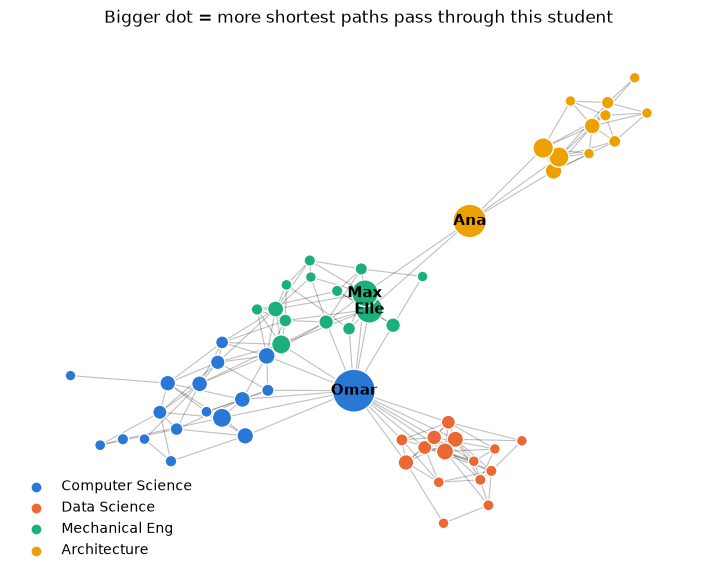

In [12]:
if ready(betweenness, "E4"):
    draw_network(U, students, highlight=["Omar", "Ana", "Elle", "Max"], size=betweenness.to_dict(),
                 title="Bigger dot = more shortest paths pass through this student")

**Write:** compare Ana's two ranks. What happens to the network without her, and what should the library learn from that?

*Your answer:*

# Part 5 · PageRank: who do the important people ask?  *(slides 21–26)*
In-degree counts **how many** students ask you. **PageRank** also cares **who** asks you: being asked by someone who is asked a lot counts for more than being asked by someone nobody asks.

Google invented it to rank web pages: a page is important if important pages link to it. The idea, slide by slide:
1. Everyone starts with the same score (1/60 here).
2. Each round, every student **passes their score** along their arrows, split equally among the people they ask.
3. A small part (15%) is shared equally among everyone (the "random jump": a reader who sometimes opens any page at random). So new score = 0.15/n + 0.85 × score received.
4. Repeat until the scores stop changing.

Scores add up to 1. A student who asks **only one** person passes their **whole** score to that one person.

**One special case:** a student who asks **nobody** has no arrows to pass along. networkx then shares that student's score equally among everyone, like the random jump. In today's data 5 students ask nobody.

```python
nx.pagerank(G)      # uses the directed graph: direction matters here
```

### E5 · Rank by PageRank
**Predict:** Nora is asked for help by only 2 students. Will she be in the top 5 by PageRank?

In [13]:
# 1. rank_table: a copy of degree_table with a new column "pagerank" from nx.pagerank(G).
rank_table = degree_table.assign(pagerank=degree_table["name"].map(nx.pagerank(G))).sort_values("pagerank", ascending=False).reset_index(drop=True)

# 2. Sort rank_table by pagerank, largest first. Display the top 6 with
#    name, major, asked_by and pagerank.
display(rank_table[["name", "major", "asked_by", "pagerank"]].head(6))

# 3. Print who asks Nora for help. And how many people Omar asks:
print("Who asks Nora:", list(G.predecessors("Nora")))
print("People Omar asks:", G.out_degree("Omar"))


,name,major,asked_by,pagerank
0,Leo,Computer Science,7,0.059573
1,Cole,Mechanical Eng,8,0.059113
2,Nora,Computer Science,2,0.053958
3,Omar,Computer Science,17,0.053357
4,Jay,Mechanical Eng,7,0.045575
5,Aria,Computer Science,4,0.042299


Who asks Nora: ['Ethan', 'Omar']
People Omar asks: 1


**Check E5**

In [14]:
if ready(rank_table, "E5"):
    check("one row per student", len(rank_table) == len(students))
    check("PageRank scores add up to 1", np.isclose(rank_table["pagerank"].sum(), 1))
    check("PageRank was computed on the directed graph G",
          np.allclose(rank_table.set_index("name")["pagerank"].sort_index(),
                      pd.Series(nx.pagerank(G)).sort_index()))
    check("sorted by pagerank, largest first", rank_table["pagerank"].is_monotonic_decreasing)

PASS  one row per student
PASS  PageRank scores add up to 1
PASS  PageRank was computed on the directed graph G
PASS  sorted by pagerank, largest first


**Write:** where is Nora, and why? Why is Omar, asked by 17 students, not first?

*Your answer:*

### What these numbers can and can't tell you
Degree, betweenness and PageRank describe **where a student sits in the network**: how many links, which routes pass through them, who asks them. They do **not** measure whether someone **knows the material** or **explains it well**. Omar is asked a lot, but that could be because he is friendly, or simply nearby. To choose good tutors you would also need other evidence: grades, feedback from the students they helped, an interview.

Network position is still useful: it tells you who can **reach** many students, and who connects groups that would otherwise be cut off.

### The AI's analysis
The library asks an AI assistant which students to recruit as paid peer tutors. It replies:

> "The most important student is simply whoever has the most connections, so recruit Omar and the next four students by degree. Ana has only 5 connections, below average, so she doesn't matter to the network. Nora is asked for help by only 2 students, so she can be ignored. PageRank is just a fancier way of counting how many people ask you, so it would give the same answer."

**Write:** find **three** problems in the AI's answer. For each one, give the evidence from your notebook.

*Your answer:*
1. Degree is not the sole measure of importance: Ana has low degree but a crucial rank of 2 in betweenness. without her the network disconnects.
2. Nora cannot be ignored. She ranks 3rd in pagerank.
3. PageRank does not give the same answer as degree. Omar has 17 askers and ranks 4th. Leo has 7 askers and ranks 1st


### Challenge tasks (optional)
1. Draw the network with dot size = PageRank (`size=rank_table.set_index("name")["pagerank"].to_dict()`). Who looks bigger than in the betweenness picture?
2. Compute `nx.closeness_centrality(U)`: 1 / (average distance to everyone else). Who can reach the whole class fastest?
3. Remove Omar from a copy of `U`. How many pieces? How does the average distance change for the biggest piece?

# Exit ticket
Answer without running more code.
1. What is the difference between degree and betweenness? Give a student from today who is low on one and high on the other.
2. Why can a student with few askers have a high PageRank?
3. In one sentence: what does breadth-first search do, and why does it find shortest paths?

*Your answers:*
1. Degree counts direct connections; betweenness measures the frequency of a node siting on a shortest path. Ana has low degree of 5 but high betweenness of rank 2.
2. If the few students asking them have high PageRank it passes on to the other students.
3. Breadth-first search explores nodes ring by ring. This guarentees that the shortest path will be found counting those rings. 


# Submit
- Restart the kernel and run all cells. Every check should print `PASS`.
- Every *Your answer* cell is filled in.
- Submit this notebook with its outputs in Brightspace by **Wednesday, November 4, 11:59 PM**.

**Friday (also self-study):** Graph Mining II, finding groups in a network and suggesting new study partners. **Your project proposal is due Friday, November 6, 11:59 PM.**